# Who answers the income survey? Reproduction

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alestainer/statistics-intuitions/blob/main/notebooks/06-who-answers-the-income-survey.ipynb)

The argument is statistical, so the data is synthetic: a made-up country of 2,000,000 households with a
skewed income distribution. Every household is invited to the survey. The only thing that goes wrong is
**who answers**.

Real published numbers are used in two places only: to give the made-up country a realistic shape, and to
size the homeless population in the last section. The seed is fixed, so every number below is the same on every run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 20261110
N_HOUSEHOLDS = 2_000_000

# Census Bureau, "Income in the United States: 2025", Table 2 (all households)
CENSUS_MEDIAN = 87_460
CENSUS_MEAN = 126_700
CENSUS_HOUSEHOLDS = 137_100_000

# HUD, 2025 Annual Homeless Assessment Report, Part 1 (one night in January 2025)
HOMELESS_TOTAL = 745_652
HOMELESS_UNSHELTERED = 266_320

rng = np.random.default_rng(SEED)

## 1. A skewed population: mean and median disagree before any survey

Incomes are drawn from a lognormal distribution. Its two parameters are set so the true median and mean
equal the Census figures. A lognormal has `mean / median = exp(sigma^2 / 2)`, which fixes `sigma`.

In [2]:
sigma = np.sqrt(2 * np.log(CENSUS_MEAN / CENSUS_MEDIAN))
mu = np.log(CENSUS_MEDIAN)
income = rng.lognormal(mu, sigma, N_HOUSEHOLDS)

true_mean = income.mean()
true_median = np.median(income)
below_mean = (income < true_mean).mean()

print(f"sigma               {sigma:.3f}")
print(f"true mean           ${true_mean:,.0f}")
print(f"true median         ${true_median:,.0f}")
print(f"mean / median       {true_mean / true_median:.2f}")
print(f"households below the mean: {below_mean:.1%}")

sigma               0.861
true mean           $126,598
true median         $87,435
mean / median       1.45
households below the mean: 66.6%


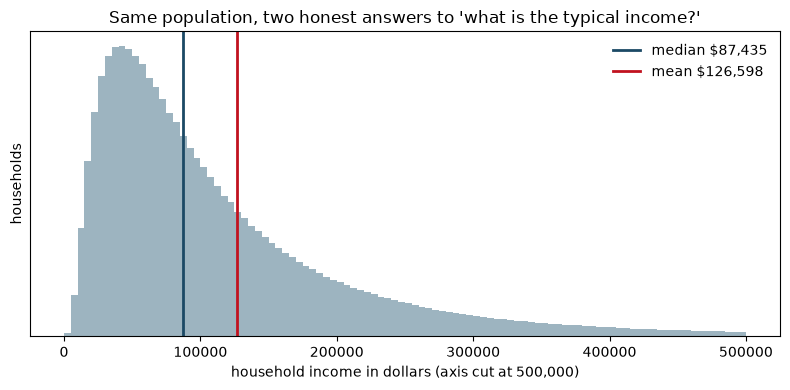

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(income, bins=np.linspace(0, 500_000, 101), color="#9db4c0")
ax.axvline(true_median, color="#1b4965", lw=2, label=f"median ${true_median:,.0f}")
ax.axvline(true_mean, color="#c1121f", lw=2, label=f"mean ${true_mean:,.0f}")
ax.set_xlabel("household income in dollars (axis cut at 500,000)")
ax.set_ylabel("households")
ax.set_yticks([])
ax.legend(frameon=False)
ax.set_title("Same population, two honest answers to 'what is the typical income?'")
fig.tight_layout()
plt.show()

## 2. Create the response bias

Each household gets an income rank from 0 (poorest) to 1 (richest). Its chance of answering depends on
that rank. In every scenario the overall response rate is 70%, so the scenarios differ only in *who* is missing.

| Scenario | Response probability |
|---|---|
| Fair | 70% for everyone |
| Poor answer less | 60% at the bottom, rising to 80% at the top |
| Rich answer less | 80% at the bottom, falling to 60% at the top |
| Both tails answer less | 60% at both ends, 80% in the middle |

In [4]:
rank = income.argsort().argsort() / (N_HOUSEHOLDS - 1)

scenarios = {
    "Fair": np.full(N_HOUSEHOLDS, 0.70),
    "Poor answer less": 0.60 + 0.20 * rank,
    "Rich answer less": 0.80 - 0.20 * rank,
    "Both tails answer less": 0.80 - 0.20 * np.abs(2 * rank - 1),
}

def run_survey(response_probability, rng):
    answered = rng.random(N_HOUSEHOLDS) < response_probability
    return income[answered]

def pct_error(estimate, truth):
    return 100 * (estimate / truth - 1)

results, samples = {}, {}
print(f"{'scenario':<24}{'answered':>9}{'mean':>11}{'error':>8}{'median':>11}{'error':>8}")
for name, probability in scenarios.items():
    sample = run_survey(probability, rng)
    samples[name] = sample
    results[name] = (
        len(sample) / N_HOUSEHOLDS,
        pct_error(sample.mean(), true_mean),
        pct_error(np.median(sample), true_median),
    )
    print(f"{name:<24}{results[name][0]:>9.1%}{sample.mean():>11,.0f}{results[name][1]:>+7.1f}%"
          f"{np.median(sample):>11,.0f}{results[name][2]:>+7.1f}%")

scenario                 answered       mean   error     median   error
Fair                        70.0%    126,550   -0.0%     87,435   +0.0%
Poor answer less            70.0%    134,930   +6.6%     94,470   +8.0%
Rich answer less            70.0%    118,356   -6.5%     81,023   -7.3%
Both tails answer less      69.9%    122,752   -3.0%     87,404   -0.0%


The same result as a picture. In each panel the grey shape is what a fair 70% survey would collect.
The black line is who actually answered. Orange marks households that are missing, green marks households that are
over-represented. The strip under each panel zooms in on the two summary numbers: the hollow marker is the truth,
the filled marker is what the survey reports. The same positions are drawn on the panel above as dotted (truth) and solid (survey) lines.

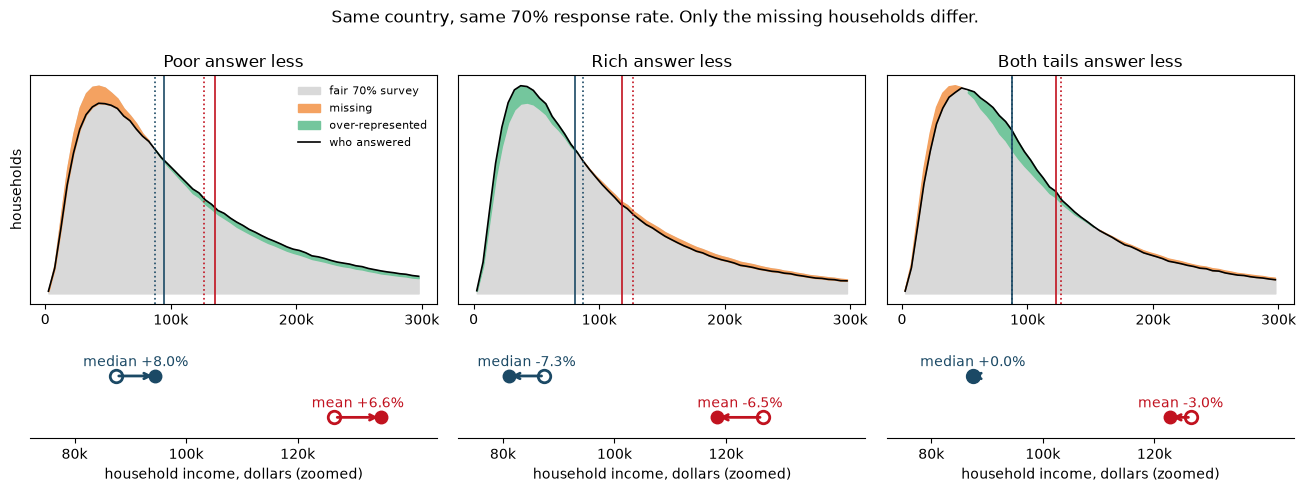

In [5]:
BLUE, RED = "#1b4965", "#c1121f"
edges = np.linspace(0, 300_000, 61)
centers = (edges[:-1] + edges[1:]) / 2
biased = ["Poor answer less", "Rich answer less", "Both tails answer less"]

def draw_shift(names, population, title, columns, zero_label=None):
    """One panel per scenario: who answered against a fair 70% sample of `population`."""
    truth_median, truth_mean = np.median(population), population.mean()
    fair_share = 0.70 * np.histogram(population, edges)[0]
    rows = -(-len(names) // columns)
    fig, axes = plt.subplots(2 * rows, columns, figsize=(4.4 * columns, 4.9 * rows), squeeze=False,
                             gridspec_kw={"height_ratios": [3, 1.25] * rows})
    for index, name in enumerate(names):
        row, column = divmod(index, columns)
        top, strip = axes[2 * row, column], axes[2 * row + 1, column]
        sample = samples[name]
        answered_counts = np.histogram(sample, edges)[0]

        top.fill_between(centers, fair_share, color="#d9d9d9", label="fair 70% survey")
        top.fill_between(centers, fair_share, answered_counts, where=answered_counts < fair_share,
                         color="#f4a261", label="missing")
        top.fill_between(centers, fair_share, answered_counts, where=answered_counts >= fair_share,
                         color="#74c69d", label="over-represented")
        top.plot(centers, answered_counts, color="black", lw=1.2, label="who answered")
        top.set_title(name)
        top.set_yticks([])
        top.set_xticks([0, 100_000, 200_000, 300_000], ["0", "100k", "200k", "300k"])
        if index == 0:
            top.set_ylabel("households")
            top.legend(frameon=False, fontsize=8, loc="upper right")
        if zero_label:
            top.set_xlim(-62_000, 312_000)
            top.text(-4_000, fair_share[0], zero_label, fontsize=8.5, ha="right", va="center", color="#b5651d")

        for height, label, truth, estimate, color in [
            (1, "median", truth_median, np.median(sample), BLUE),
            (0, "mean", truth_mean, sample.mean(), RED),
        ]:
            shift = round(pct_error(estimate, truth), 1) + 0.0
            strip.annotate("", xy=(estimate, height), xytext=(truth, height),
                           arrowprops=dict(arrowstyle="->", color=color, lw=2))
            strip.plot(truth, height, "o", mfc="white", mec=color, ms=9, mew=2)
            strip.plot(estimate, height, "o", color=color, ms=9)
            strip.text((truth + estimate) / 2, height + 0.33, f"{label} {shift:+.1f}%", va="center", ha="center",
                       color=color, fontsize=10)
            for value, style in [(truth, ":"), (estimate, "-")]:
                top.axvline(value, color=color, ls=style, lw=1.2)
        strip.set_xlim(72_000, 145_000)
        strip.set_ylim(-0.5, 1.8)
        strip.set_yticks([])
        strip.set_xticks([80_000, 100_000, 120_000], ["80k", "100k", "120k"])
        strip.set_xlabel("household income, dollars (zoomed)")
        for side in ("top", "left", "right"):
            strip.spines[side].set_visible(False)
    fig.suptitle(title, y=0.995)
    fig.tight_layout()
    plt.show()

draw_shift(biased, income, "Same country, same 70% response rate. Only the missing households differ.", columns=3)

Reading the table:

- **Fair** nonresponse costs nothing except sample size. A 70% response rate is not a problem by itself.
- **Poor answer less** pushes both numbers up.
- **Rich answer less** pushes both numbers down.
- **Both tails answer less** leaves the median where it was and drags the mean down. The median only
  cares whether the missing households are balanced on both sides of it. The mean cares how many dollars went missing.

## 3. How big a gap does it take?

Keep the "poor answer less" shape and change only the gap between the top and bottom response rates.

In [6]:
gaps = np.arange(0, 41, 5)  # percentage points between richest and poorest
sweep_rng = np.random.default_rng(SEED + 1)
mean_errors, median_errors = [], []
for gap in gaps:
    probability = 0.70 + (gap / 100) * (rank - 0.5)
    sample = run_survey(probability, sweep_rng)
    mean_errors.append(pct_error(sample.mean(), true_mean))
    median_errors.append(pct_error(np.median(sample), true_median))

for gap, mean_error, median_error in zip(gaps, mean_errors, median_errors):
    print(f"gap {gap:>2} points   mean {mean_error:+5.1f}%   median {median_error:+5.1f}%")

gap  0 points   mean  -0.0%   median  -0.0%
gap  5 points   mean  +1.7%   median  +2.0%
gap 10 points   mean  +3.2%   median  +3.9%
gap 15 points   mean  +4.8%   median  +6.0%
gap 20 points   mean  +6.6%   median  +8.0%
gap 25 points   mean  +8.1%   median +10.0%
gap 30 points   mean  +9.8%   median +12.2%
gap 35 points   mean +11.4%   median +14.3%
gap 40 points   mean +13.0%   median +16.4%


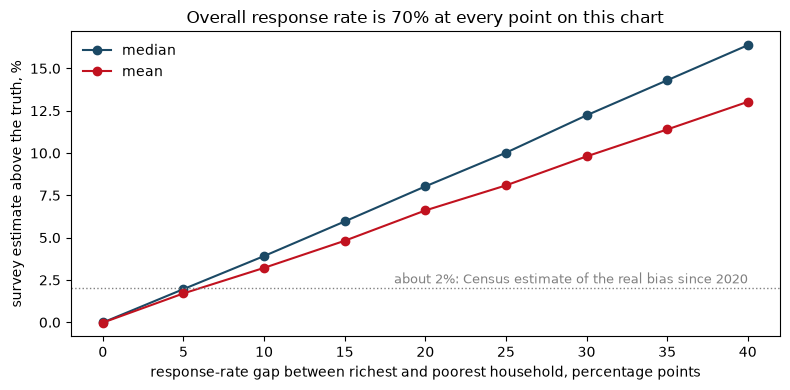

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gaps, median_errors, "o-", color="#1b4965", label="median")
ax.plot(gaps, mean_errors, "o-", color="#c1121f", label="mean")
ax.axhline(2, color="grey", ls=":", lw=1)
ax.text(40, 2.3, "about 2%: Census estimate of the real bias since 2020", ha="right", color="grey", fontsize=9)
ax.set_xlabel("response-rate gap between richest and poorest household, percentage points")
ax.set_ylabel("survey estimate above the truth, %")
ax.set_title("Overall response rate is 70% at every point on this chart")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 4. Does reweighting fix it?

Surveys do not know the income of a household that did not answer. They know things *related* to income,
such as the neighbourhood. Here every household gets a neighbourhood tier (1 to 5) that follows income
imperfectly. Respondents are then reweighted so each tier counts as much as it does in the population.

In [8]:
def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    return values[order][np.searchsorted(cumulative, cumulative[-1] / 2)]

weight_rng = np.random.default_rng(SEED + 2)
noisy_signal = np.log(income) + weight_rng.normal(0, sigma, N_HOUSEHOLDS)
tier = np.searchsorted(np.quantile(noisy_signal, [0.2, 0.4, 0.6, 0.8]), noisy_signal)
print(f"correlation between tier and log income: {np.corrcoef(tier, np.log(income))[0, 1]:.2f}")

answered = weight_rng.random(N_HOUSEHOLDS) < scenarios["Poor answer less"]
sample, sample_tier = income[answered], tier[answered]

tier_response_rate = np.array([answered[tier == t].mean() for t in range(5)])
weights = 1 / tier_response_rate[sample_tier]

raw_mean_error = pct_error(sample.mean(), true_mean)
raw_median_error = pct_error(np.median(sample), true_median)
weighted_mean_error = pct_error(np.average(sample, weights=weights), true_mean)
weighted_median_error = pct_error(weighted_median(sample, weights), true_median)

print("response rate by tier:", np.round(tier_response_rate, 3))
print(f"unweighted   mean {raw_mean_error:+.1f}%   median {raw_median_error:+.1f}%")
print(f"reweighted   mean {weighted_mean_error:+.1f}%   median {weighted_median_error:+.1f}%")

correlation between tier and log income: 0.67


response rate by tier: [0.643 0.675 0.699 0.724 0.758]
unweighted   mean +6.7%   median +8.1%
reweighted   mean +3.5%   median +4.5%


Reweighting removes the part of the bias that the tier can see. Inside each tier the poorer households
are still the ones missing, and nothing observable separates them from their neighbours who answered.

## 5. Households that were never invited

Response bias is about people who were asked and stayed silent. People with no address are not asked at all.
The worst case for the statistics: treat every homeless person HUD counted as a separate household with zero income,
and add them to the population.

In [9]:
def add_zero_income_households(count_in_real_country):
    share = count_in_real_country / (CENSUS_HOUSEHOLDS + count_in_real_country)
    synthetic_count = round(share / (1 - share) * N_HOUSEHOLDS)
    return share, np.concatenate([income, np.zeros(synthetic_count)])

homeless_results = {}
for label, count in [("unsheltered only", HOMELESS_UNSHELTERED), ("all homeless", HOMELESS_TOTAL)]:
    share, everyone = add_zero_income_households(count)
    homeless_results[label] = (
        100 * share,
        pct_error(true_mean, everyone.mean()),
        pct_error(true_median, np.median(everyone)),
    )
    print(f"{label:<18} {share:.2%} of households   "
          f"survey mean too high by {homeless_results[label][1]:.2f}%   "
          f"median too high by {homeless_results[label][2]:.2f}%")

unsheltered only   0.19% of households   survey mean too high by 0.19%   median too high by 0.21%


all homeless       0.54% of households   survey mean too high by 0.54%   median too high by 0.59%


The same picture as in section 2, with one change: the truth now includes every homeless person as a zero-income
household. None of them can answer, in any scenario. They are the orange spike at zero. The first panel has no
response bias at all, so its shift is the effect of the missing homeless alone.

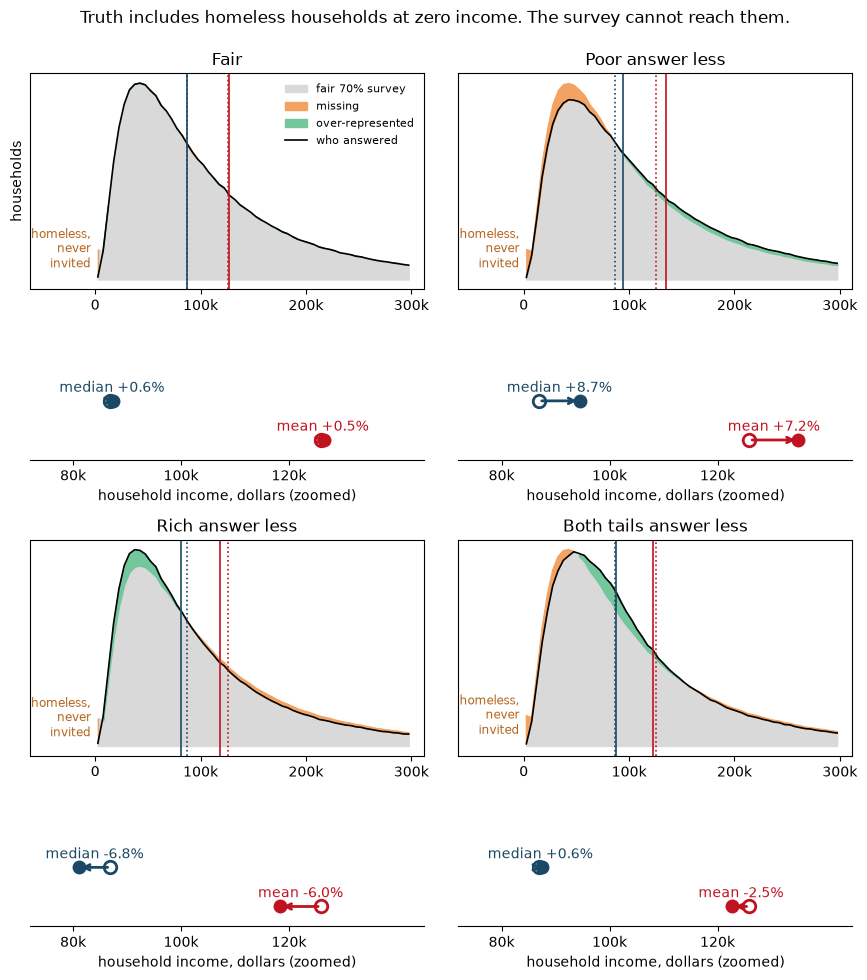

Fair                     mean +0.5%   median +0.6%
Poor answer less         mean +7.2%   median +8.7%
Rich answer less         mean -6.0%   median -6.8%
Both tails answer less   mean -2.5%   median +0.6%


In [10]:
_, everyone = add_zero_income_households(HOMELESS_TOTAL)
draw_shift(["Fair"] + biased, everyone, "Truth includes homeless households at zero income. The survey cannot reach them.", columns=2,
           zero_label="homeless,\nnever\ninvited")

with_homeless = {
    name: (pct_error(samples[name].mean(), everyone.mean()), pct_error(np.median(samples[name]), np.median(everyone)))
    for name in ["Fair"] + biased
}
for name, (mean_error, median_error) in with_homeless.items():
    print(f"{name:<24} mean {mean_error:+.1f}%   median {median_error:+.1f}%")

## 6. How noisy is the homeless count itself?

The 745,652 above is also a survey result. HUD adds up one-night counts from about 385 local areas.
The **sheltered** number comes from shelter bed records. The **unsheltered** number comes from staff and
volunteers who walk the streets. Both describe the same area in the same year, so the first is a yardstick for the second.

The file `hud-pit-counts-by-coc.csv` holds HUD's published counts per area and year, extracted from HUD's workbook
by `extract_hud_pit.py` in the same folder.

In [11]:
from pathlib import Path
import pandas as pd

PIT_FILE = "data/06-who-answers-the-income-survey/hud-pit-counts-by-coc.csv"
RAW = "https://raw.githubusercontent.com/Alestainer/statistics-intuitions/main/"
local = [path for path in (Path("..") / PIT_FILE, Path(PIT_FILE)) if path.exists()]
pit = pd.read_csv(local[0] if local else RAW + PIT_FILE)

latest = pit[pit.year == 2025]
assert latest.overall.sum() == HOMELESS_TOTAL and latest.unsheltered.sum() == HOMELESS_UNSHELTERED
print(f"{pit.coc.nunique()} areas, {pit.year.min()} to {pit.year.max()}; 2025 totals match HUD's report")

413 areas, 2007 to 2025; 2025 totals match HUD's report


Compare each area's count with its own count one year earlier. Rules, fixed before looking at the result:

- both years must be a full count of sheltered and unsheltered people (HUD labels the years where an area skipped the street count);
- the area must have at least 100 sheltered and 100 unsheltered people in the earlier year, so small numbers do not dominate;
- comparisons that touch 2021 are dropped, because the pandemic stopped most street counts.

In [12]:
FULL_COUNT = ("Sheltered and Unsheltered Count", "Sheltered and full unsheltered count")
MIN_PEOPLE = 100

this_year = pit[pit.count_type.isin(FULL_COUNT)]
last_year = this_year.assign(year=this_year.year + 1)
pairs = this_year.merge(last_year, on=["coc", "year"], suffixes=("", "_before"))
pairs = pairs[
    (pairs.sheltered_before >= MIN_PEOPLE)
    & (pairs.unsheltered_before >= MIN_PEOPLE)
    & (pairs.sheltered > 0)
    & (pairs.unsheltered > 0)
    & ~pairs.year.isin([2021, 2022])
]

change = pd.DataFrame({
    "sheltered": (pairs.sheltered / pairs.sheltered_before - 1).abs(),
    "unsheltered": (pairs.unsheltered / pairs.unsheltered_before - 1).abs(),
})
swing = {kind: (100 * change[kind].median(), 100 * (change[kind] > 0.25).mean()) for kind in change}

print(f"{len(pairs)} year-to-year comparisons in {pairs.coc.nunique()} areas, {pairs.year.min() - 1} to {pairs.year.max()}")
for kind, (typical, big) in swing.items():
    print(f"{kind:<12} typical yearly change {typical:4.1f}%   changed by more than 25%: {big:4.1f}% of the time")

2129 year-to-year comparisons in 280 areas, 2009 to 2025
sheltered    typical yearly change  9.4%   changed by more than 25%: 15.3% of the time
unsheltered  typical yearly change 21.0%   changed by more than 25%: 42.6% of the time


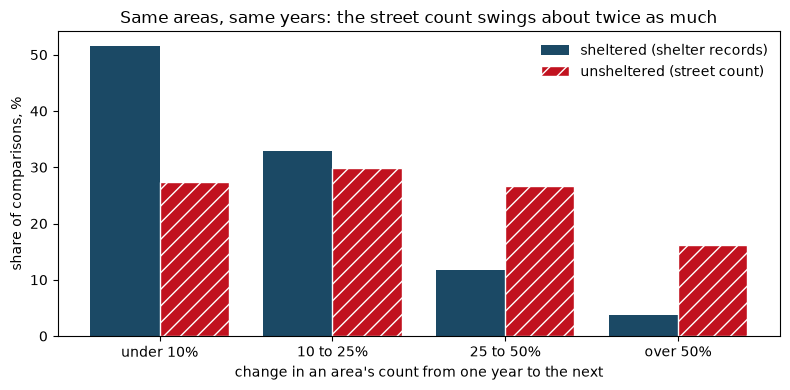

In [13]:
bins = [0, 0.10, 0.25, 0.50, np.inf]
labels = ["under 10%", "10 to 25%", "25 to 50%", "over 50%"]
shares = {kind: 100 * np.histogram(change[kind], bins)[0] / len(change) for kind in change}

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(labels))
ax.bar(x - 0.2, shares["sheltered"], 0.4, color="#1b4965", label="sheltered (shelter records)")
ax.bar(x + 0.2, shares["unsheltered"], 0.4, color="#c1121f", hatch="//", edgecolor="white", label="unsheltered (street count)")
ax.set_xticks(x, labels)
ax.set_xlabel("change in an area's count from one year to the next")
ax.set_ylabel("share of comparisons, %")
ax.set_title("Same areas, same years: the street count swings about twice as much")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Some of that swing is real change. One way to separate out the measurement error: a real change tends to stay,
while an error tends to reverse the next year. If a count is `truth + error`, the covariance between one year's
change and the next year's change equals minus the error variance. So the size of the reversal gives the size of the error.
Changes are in log units; a few changes beyond a factor of 4.5 are left out so they do not decide the answer.

In [14]:
def error_from_reversals(column):
    wide = pairs.assign(step=np.log(pairs[column] / pairs[column + "_before"])).pivot(index="coc", columns="year", values="step")
    first, second = [], []
    for year in wide.columns:
        if year + 1 in wide.columns:
            both = wide[[year, year + 1]].dropna()
            first += list(both[year])
            second += list(both[year + 1])
    first, second = np.array(first), np.array(second)
    keep = (np.abs(first) < 1.5) & (np.abs(second) < 1.5)
    covariance = np.cov(first[keep], second[keep])[0, 1]
    return keep.sum(), 100 * np.sqrt(-covariance)

count_error = {}
for kind in ("sheltered", "unsheltered"):
    used, count_error[kind] = error_from_reversals(kind)
    print(f"{kind:<12} random error in one area's count: about {count_error[kind]:.0f}%   ({used} pairs of consecutive changes)")

sheltered    random error in one area's count: about 8%   (1542 pairs of consecutive changes)
unsheltered  random error in one area's count: about 14%   (1527 pairs of consecutive changes)


This method only sees error that changes from year to year. If the street count misses the same share of
people every year, the numbers look stable and are still too low. Random error mostly cancels in the national total.
A consistent undercount does not.

### Does the noise say how many people are missed?

Not exactly, but it gives a floor. A street count can miss people; it cannot find more people than exist.
So if the same area reports very different numbers in neighbouring years, the low years must have missed
people that the high year found. For each area, compare every count with the best count in the three-year window around it.
The sheltered count gets the same treatment as a control, because real change also creates a gap.

In [15]:
def gap_to_best_neighbour(column):
    wide = pairs.pivot(index="coc", columns="year", values=column)
    before = pairs.pivot(index="coc", columns="year", values=column + "_before")
    gaps = []
    for year in wide.columns:
        if year + 1 in wide.columns:
            window = pd.concat([before[year], wide[year], wide[year + 1]], axis=1).dropna()
            gaps += list(1 - window.iloc[:, 1] / window.max(axis=1))
    return 100 * np.mean(gaps)

best_gap = {kind: gap_to_best_neighbour(kind) for kind in ("sheltered", "unsheltered")}
for kind, gap in best_gap.items():
    print(f"{kind:<12} an average count is {gap:.1f}% below the best count in its three-year window")
print(f"extra gap in the street count: {best_gap['unsheltered'] - best_gap['sheltered']:.1f} points")

sheltered    an average count is 9.6% below the best count in its three-year window
unsheltered  an average count is 16.1% below the best count in its three-year window
extra gap in the street count: 6.5 points


The extra gap is a floor under the undercount, and a low one. It assumes the best year found everyone, which
no street count does, and it cannot see people who are missed every year. To get the level you need an independent
check, such as decoys placed among the people to be counted.

## 7. Households that never form

A household is everyone who lives in one housing unit. An adult who lives with their parents is not a separate
household, whatever the reason, and their income is added to the parents' income.

Start from the same 2,000,000 incomes, but read them as "households that would exist if everyone could afford their
own place". Then one in ten of them, all from the lower-income half, moves in with a randomly chosen other household.
Nobody's income changes.

In [16]:
merge_rng = np.random.default_rng(SEED + 3)
MOVER_SHARE = 0.10

lower_half = np.flatnonzero(rank < 0.5)
movers = merge_rng.choice(lower_half, int(MOVER_SHARE * N_HOUSEHOLDS), replace=False)
stays = np.ones(N_HOUSEHOLDS, dtype=bool)
stays[movers] = False
hosts = merge_rng.choice(np.flatnonzero(stays), len(movers), replace=False)

observed = income.copy()
observed[hosts] += income[movers]
observed = observed[stays]

merged_mean_error = pct_error(observed.mean(), true_mean)
merged_median_error = pct_error(np.median(observed), true_median)
print(f"households before: {N_HOUSEHOLDS:,}   after: {len(observed):,}")
print(f"mean household income    ${true_mean:,.0f} -> ${observed.mean():,.0f}  ({merged_mean_error:+.1f}%)")
print(f"median household income  ${true_median:,.0f} -> ${np.median(observed):,.0f}  ({merged_median_error:+.1f}%)")

households before: 2,000,000   after: 1,800,000
mean household income    $126,598 -> $140,665  (+11.1%)
median household income  $87,435 -> $103,608  (+18.5%)


Total income is unchanged and both statistics rise. The survey can be perfect and this still happens, because it is
not an error in the survey. It is a consequence of counting households instead of people.

## Checks

These assertions pin the numbers quoted in the article. If one fails, the article and the notebook disagree.

In [17]:
EXPECT_BELOW_MEAN = 66.6
EXPECT_SCENARIOS = {  # (mean error %, median error %)
    "Fair": (0.0, 0.0),
    "Poor answer less": (6.6, 8.0),
    "Rich answer less": (-6.5, -7.3),
    "Both tails answer less": (-3.0, 0.0),
}
EXPECT_GAP5 = (1.7, 2.0)
EXPECT_WEIGHTED = (3.5, 4.5)
EXPECT_HOMELESS_MEDIAN = 0.59
EXPECT_SWING = {"sheltered": (9.4, 15.3), "unsheltered": (21.0, 42.6)}  # (typical change %, share over 25%)
EXPECT_COUNT_ERROR = {"sheltered": 8, "unsheltered": 14}
EXPECT_BEST_GAP = {"sheltered": 9.6, "unsheltered": 16.1}
EXPECT_MERGED = (11.1, 18.5)
EXPECT_WITH_HOMELESS = {  # (mean error %, median error %) against a truth that includes homeless households
    "Fair": (0.5, 0.6),
    "Poor answer less": (7.2, 8.7),
    "Rich answer less": (-6.0, -6.8),
    "Both tails answer less": (-2.5, 0.6),
}

def close(value, expected, tolerance=0.15):
    return abs(value - expected) <= tolerance

assert close(100 * below_mean, EXPECT_BELOW_MEAN)
for name, (mean_error, median_error) in EXPECT_SCENARIOS.items():
    assert close(results[name][1], mean_error), (name, results[name])
    assert close(results[name][2], median_error), (name, results[name])
assert close(mean_errors[1], EXPECT_GAP5[0]) and close(median_errors[1], EXPECT_GAP5[1])
assert close(weighted_mean_error, EXPECT_WEIGHTED[0]) and close(weighted_median_error, EXPECT_WEIGHTED[1])
assert close(homeless_results["all homeless"][2], EXPECT_HOMELESS_MEDIAN, 0.03)
for kind in EXPECT_SWING:
    assert close(swing[kind][0], EXPECT_SWING[kind][0]) and close(swing[kind][1], EXPECT_SWING[kind][1])
    assert round(count_error[kind]) == EXPECT_COUNT_ERROR[kind]
    assert close(best_gap[kind], EXPECT_BEST_GAP[kind])
for name, (mean_error, median_error) in EXPECT_WITH_HOMELESS.items():
    assert close(with_homeless[name][0], mean_error) and close(with_homeless[name][1], median_error), name
assert close(merged_mean_error, EXPECT_MERGED[0]) and close(merged_median_error, EXPECT_MERGED[1])
print("all article numbers reproduced")

all article numbers reproduced
